In [5]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
# Localiser le dossier dataset, indépendamment du répertoire de lancement de Jupyter
project_root = Path.cwd() if (Path.cwd() / "dataset").exists() else Path.cwd().parent
data_dir = project_root / "dataset"

dfs = []

for year in range(2011, 2016):
    df_year = pd.read_csv(data_dir / f"gt_{year}.csv")

    df_year["year"] = year

    dfs.append(df_year)

df = pd.concat(dfs, ignore_index=True)

df.head()

,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX,year
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952,2011
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377,2011
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776,2011
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505,2011
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028,2011


In [7]:
print("Dimensions :", df.shape)
print("Nombre d'observations par année :")
print(df["year"].value_counts().sort_index())

Dimensions : (36733, 12)
Nombre d'observations par année :
year
2011    7411
2012    7628
2013    7152
2014    7158
2015    7384
Name: count, dtype: int64


In [8]:
output_dir = project_root / "data/processed"
output_dir.mkdir(parents=True, exist_ok=True)

df.to_csv(
    output_dir / "gas_turbine_combined.csv",
    index=False
)

| Variable | Signification (anglais) | Signification (français) | Unité |
|----------|--------------------------|---------------------------|-------|
| AT | Ambient Temperature | Température ambiante | °C |
| AP | Ambient Pressure | Pression atmosphérique | mbar |
| AH | Ambient Humidity | Humidité relative de l'air | % |
| AFDP | Air Filter Differential Pressure | Différence de pression au niveau du filtre à air | mbar |
| GTEP | Gas Turbine Exhaust Pressure | Pression d'échappement de la turbine à gaz | mbar |
| TIT | Turbine Inlet Temperature | Température des gaz à l'entrée de la turbine | °C |
| TAT | Turbine After Temperature | Température des gaz après la turbine | °C |
| TEY | Turbine Energy Yield | Énergie produite par la turbine | MWh |
| CDP | Compressor Discharge Pressure | Pression à la sortie du compresseur | mbar (à vérifier) |
| CO | Carbon Monoxide | Concentration de monoxyde de carbone | mg/m³ |
| NOX | Nitrogen Oxides | Concentration d'oxydes d'azote | mg/m³ |
| year | Year | Année d'enregistrement | — |

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36733 entries, 0 to 36732
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AT      36733 non-null  float64
 1   AP      36733 non-null  float64
 2   AH      36733 non-null  float64
 3   AFDP    36733 non-null  float64
 4   GTEP    36733 non-null  float64
 5   TIT     36733 non-null  float64
 6   TAT     36733 non-null  float64
 7   TEY     36733 non-null  float64
 8   CDP     36733 non-null  float64
 9   CO      36733 non-null  float64
 10  NOX     36733 non-null  float64
 11  year    36733 non-null  int64  
dtypes: float64(11), int64(1)
memory usage: 3.4 MB


In [10]:
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing (%)": df.isnull().mean() * 100
})

missing_values

,Missing Count,Missing (%)
AT,0,0.0
AP,0,0.0
AH,0,0.0
AFDP,0,0.0
GTEP,0,0.0
TIT,0,0.0
TAT,0,0.0
TEY,0,0.0
CDP,0,0.0
CO,0,0.0


In [11]:
df.duplicated().sum()

np.int64(7)

In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
AT,36733.0,17.712726,7.447451,-6.234800,11.7810,17.8010,23.6650,37.1030
AP,36733.0,1013.070165,6.463346,985.850000,1008.8000,1012.6000,1017.0000,1036.6000
AH,36733.0,77.867015,14.461355,24.085000,68.1880,80.4700,89.3760,100.2000
AFDP,36733.0,3.925518,0.773936,2.087400,3.3556,3.9377,4.3769,7.6106
GTEP,36733.0,25.563801,4.195957,17.698000,23.1290,25.1040,29.0610,40.7160
TIT,36733.0,1081.428084,17.536373,1000.800000,1071.8000,1085.9000,1097.0000,1100.9000
TAT,36733.0,546.158517,6.842360,511.040000,544.7200,549.8800,550.0400,550.6100
TEY,36733.0,133.506404,15.618634,100.020000,124.4500,133.7300,144.0800,179.5000
CDP,36733.0,12.060525,1.088795,9.851800,11.4350,11.9650,12.8550,15.1590
CO,36733.0,2.372468,2.262672,0.000388,1.1824,1.7135,2.8429,44.1030


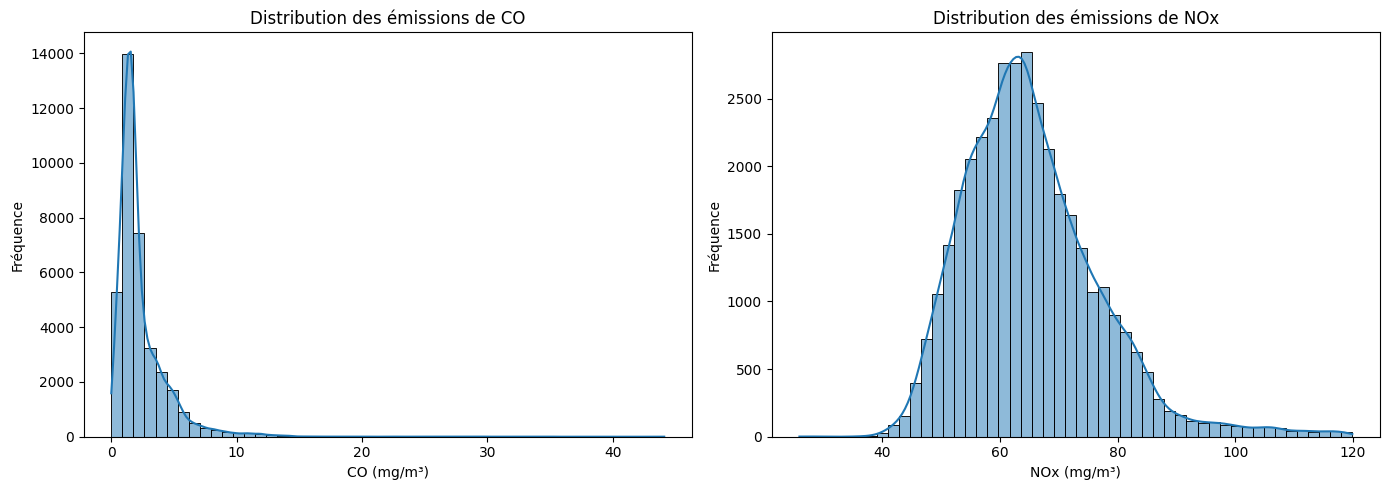

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df["CO"],
    bins=50,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribution des émissions de CO")
axes[0].set_xlabel("CO (mg/m³)")
axes[0].set_ylabel("Fréquence")

sns.histplot(
    df["NOX"],
    bins=50,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Distribution des émissions de NOx")
axes[1].set_xlabel("NOx (mg/m³)")
axes[1].set_ylabel("Fréquence")

plt.tight_layout()
plt.show()

### Interprétation des distributions des émissions

**CO (monoxyde de carbone)**
- Distribution fortement asymétrique vers la droite.
- La majorité des concentrations sont faibles, principalement inférieures à 5 mg/m³.
- La moyenne (2,37 mg/m³) est supérieure à la médiane (1,71 mg/m³).
- Présence de valeurs extrêmes potentielles atteignant 44,10 mg/m³.

**NOx (oxydes d'azote)**
- Distribution approximativement en cloche, avec une asymétrie positive modérée.
- La majorité des observations sont concentrées autour de 55 à 75 mg/m³.
- Moyenne de 65,29 mg/m³ et médiane de 63,85 mg/m³.
- Quelques concentrations élevées atteignent 119,91 mg/m³.

**Conclusion :**

Les émissions de CO et de NOx présentent des distributions différentes. Le CO se caractérise par une forte concentration de valeurs faibles et une longue queue à droite, tandis que les NOx ont une distribution plus régulière autour de leur valeur centrale.

Ces différences justifient une étude des valeurs atypiques et des relations entre les émissions et les conditions de fonctionnement de la turbine.

### Analyser les valeurs extrêmes avec les boxplots

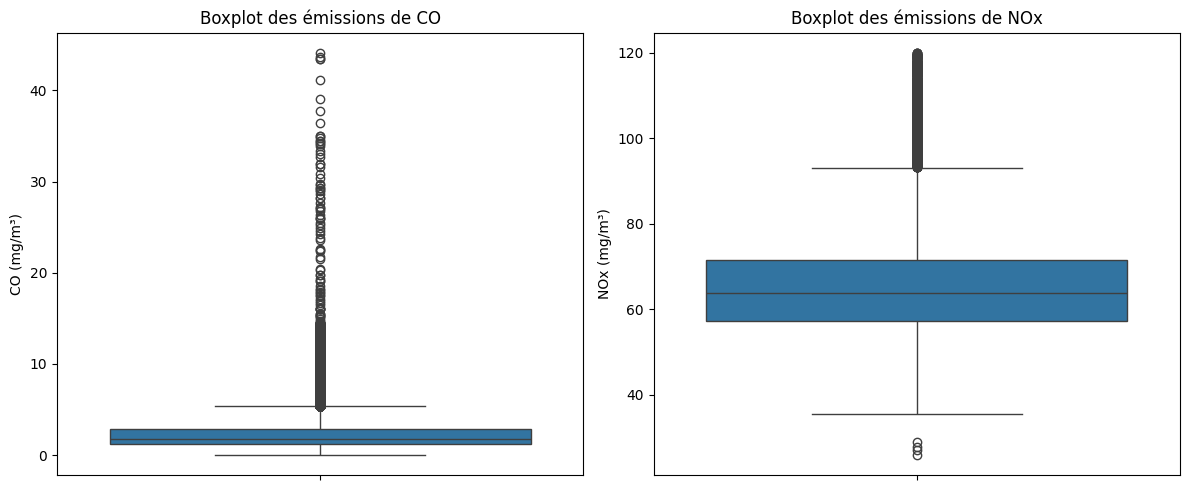

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df["CO"], ax=axes[0])
axes[0].set_title("Boxplot des émissions de CO")
axes[0].set_ylabel("CO (mg/m³)")

sns.boxplot(y=df["NOX"], ax=axes[1])
axes[1].set_title("Boxplot des émissions de NOx")
axes[1].set_ylabel("NOx (mg/m³)")

plt.tight_layout()
plt.show()

### Analyse des valeurs atypiques — Boxplots

**CO :**
- Distribution fortement asymétrique vers la droite.
- 50 % des observations sont comprises entre 1,18 et 2,84 mg/m³.
- La limite supérieure IQR est d'environ 5,33 mg/m³.
- De nombreuses observations dépassent cette limite, avec un maximum de 44,10 mg/m³.

**NOx :**
- Distribution plus concentrée autour de la médiane (63,85 mg/m³).
- 50 % des observations sont comprises entre 57,16 et 71,55 mg/m³.
- Les limites IQR sont d'environ 35,58 et 93,13 mg/m³.
- Des valeurs atypiques existent aux deux extrémités de la distribution.

**Conclusion :**

Les deux polluants présentent des valeurs atypiques, particulièrement marquées pour le CO. Ces observations ne doivent pas être supprimées automatiquement, car elles peuvent correspondre à des conditions réelles de fonctionnement de la turbine.

Une analyse des relations entre les émissions et les paramètres opérationnels est nécessaire pour mieux comprendre leur origine.

In [15]:
for col in ["CO", "NOX"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"\nVariable : {col}")
    print(f"Limite inférieure : {lower:.2f}")
    print(f"Limite supérieure : {upper:.2f}")
    print(f"Nombre de valeurs atypiques : {len(outliers)}")
    print(f"Pourcentage : {len(outliers) / len(df) * 100:.2f}%")


Variable : CO
Limite inférieure : -1.31
Limite supérieure : 5.33
Nombre de valeurs atypiques : 2655
Pourcentage : 7.23%

Variable : NOX
Limite inférieure : 35.58
Limite supérieure : 93.13
Nombre de valeurs atypiques : 936
Pourcentage : 2.55%


### Analyse des valeurs atypiques

La méthode IQR a identifié :

- **CO :** 2 655 observations atypiques (7,23 %), toutes situées
  au-dessus du seuil supérieur de 5,33 mg/m³.
- **NOx :** 936 observations atypiques (2,55 %), situées
  en dehors de l'intervalle [35,58 ; 93,13] mg/m³.

La distribution du CO présente davantage de valeurs atypiques
selon la méthode IQR que celle des NOx.

Ces observations sont conservées pour les analyses suivantes,
car elles peuvent correspondre à des conditions réelles de
fonctionnement de la turbine.

La prochaine étape consiste à rechercher des relations entre
les paramètres opérationnels et les concentrations polluantes.

#### Analyse bivariée : comprendre les relations entre les capteurs et les émissions

##### Comment leurs concentrations varient en fonction des paramètres de fonctionnement de la turbine ? 

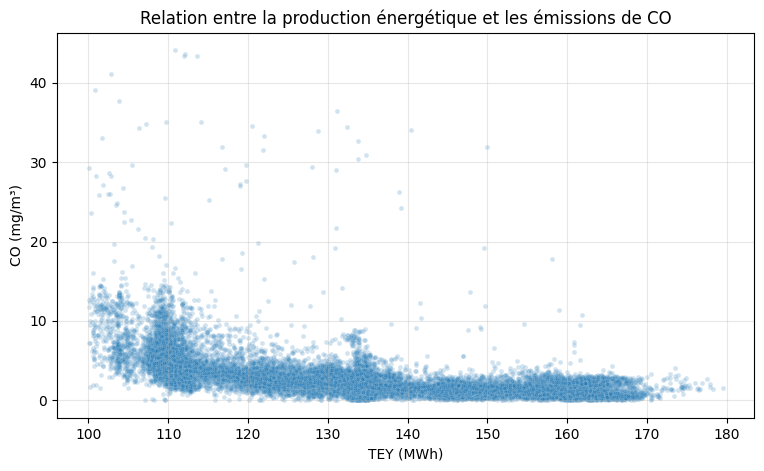

In [16]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="TEY",
    y="CO",
    alpha=0.2,
    s=12
)

plt.title("Relation entre la production énergétique et les émissions de CO")
plt.xlabel("TEY (MWh)")
plt.ylabel("CO (mg/m³)")
plt.grid(alpha=0.3)

plt.show()

In [17]:
df[["TEY", "CO"]].corr(method="pearson")

,TEY,CO
TEY,1.000000,-0.569813
CO,-0.569813,1.000000


### Analyse bivariée : TEY vs CO

L'analyse du nuage de points entre la production énergétique de la turbine (TEY) et les émissions de monoxyde de carbone (CO) révèle une corrélation négative modérée, avec un coefficient de Pearson de **−0,5698**.

**Observations :**
- Les concentrations de CO ont globalement tendance à diminuer lorsque TEY augmente.
- À faible production énergétique, les émissions présentent une forte dispersion et plusieurs valeurs extrêmes.
- À production élevée, les concentrations de CO sont généralement faibles et moins dispersées.
- La relation semble non linéaire, avec une diminution initiale suivie d'une tendance à la stabilisation.

**Interprétation physique :**

Cette tendance pourrait être liée aux conditions de combustion à différentes charges de fonctionnement. Une combustion moins complète à faible charge pourrait contribuer à des émissions plus élevées de CO.

**Conclusion :**

TEY semble être une variable explicative intéressante pour la prédiction du CO. Toutefois, la corrélation observée ne démontre pas une relation de causalité. Une analyse multivariée sera nécessaire pour tenir compte des autres paramètres de fonctionnement.

#### La température d'entrée de la turbine (TIT) est-elle associée aux émissions de NOx ?

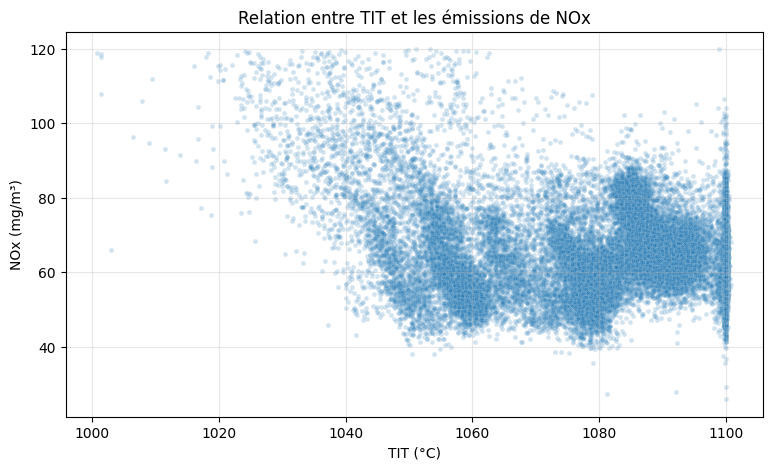

Corrélation TIT–NOx : -0.21386547079766557


In [18]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="TIT",
    y="NOX",
    alpha=0.2,
    s=12
)

plt.title("Relation entre TIT et les émissions de NOx")
plt.xlabel("TIT (°C)")
plt.ylabel("NOx (mg/m³)")
plt.grid(alpha=0.3)

plt.show()

print("Corrélation TIT–NOx :",
      df["TIT"].corr(df["NOX"]))

### Analyse bivariée : TIT vs NOx

L'analyse de la relation entre la température d'entrée de la turbine (TIT) et les émissions de NOx révèle une **corrélation de Pearson de −0,2139**, indiquant une faible association linéaire négative.

**Observations :**
- Les concentrations de NOx présentent une dispersion importante pour plusieurs valeurs de TIT.
- Les valeurs élevées de NOx apparaissent notamment à des températures d'entrée relativement faibles.
- Une concentration importante d'observations est visible près de 1 100 °C.
- Le nuage de points semble présenter plusieurs zones de concentration, pouvant suggérer différents régimes de fonctionnement.

**Interprétation physique :**

Bien que les températures de flamme élevées favorisent généralement la formation des NOx thermiques, TIT ne correspond pas directement à la température maximale de flamme.

Les émissions dépendent également de la pression, du mélange air-combustible et des conditions opérationnelles.

**Conclusion :**

TIT seule présente une faible association linéaire avec NOx. Une analyse multivariée est nécessaire pour mieux comprendre les facteurs liés aux émissions et les interactions possibles entre les capteurs.

#### Analyse multivariée avec une matrice de corrélation

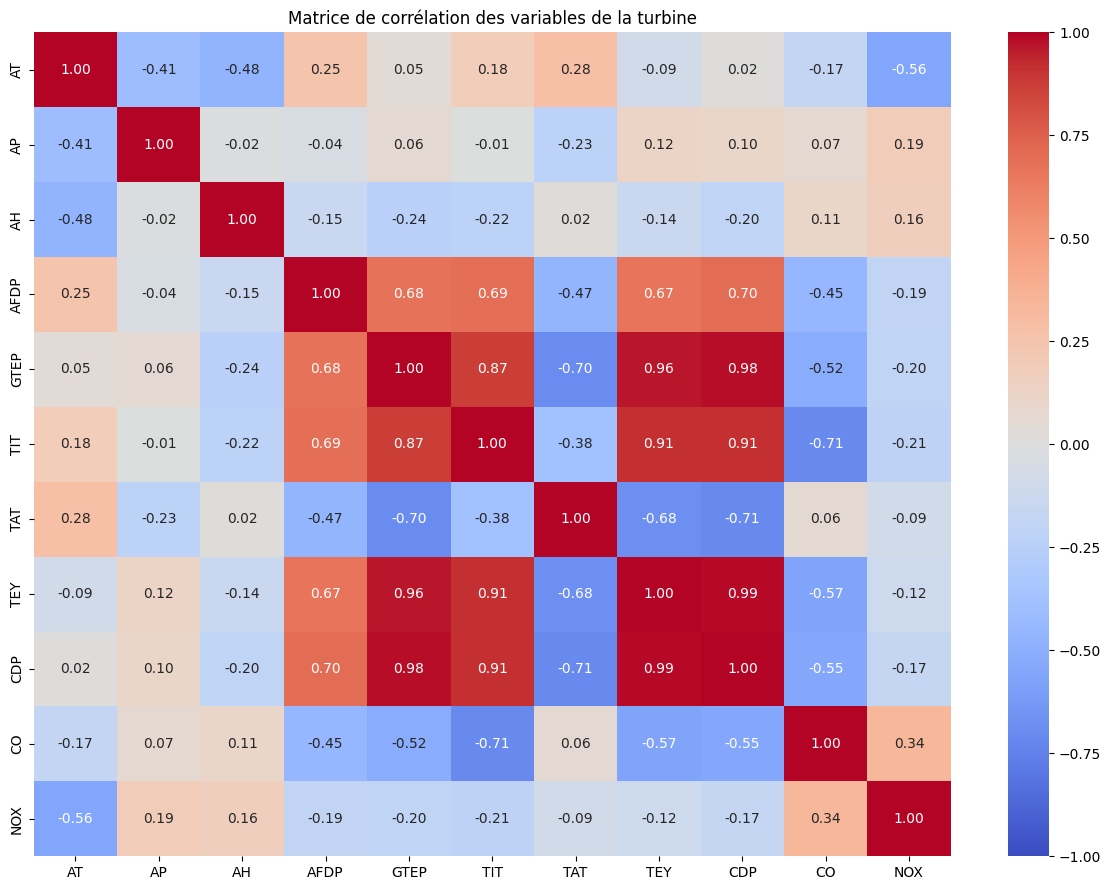

In [19]:
# Exclure l'année pour étudier uniquement les mesures physiques
corr = df.drop(columns="year").corr(method="pearson")

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Matrice de corrélation des variables de la turbine")
plt.tight_layout()
plt.show()

### Analyse multivariée — Matrice de corrélation

L'analyse de la matrice de corrélation de Pearson met en évidence plusieurs relations entre les paramètres de fonctionnement de la turbine et les émissions polluantes.

**Émissions de CO :**
- TIT présente la corrélation négative la plus forte avec CO (r = −0,71).
- TEY (−0,57), CDP (−0,55) et GTEP (−0,52) présentent également des corrélations négatives modérées.
- Ces résultats suggèrent que les conditions thermiques et opérationnelles de la turbine sont associées aux variations des émissions de CO.

**Émissions de NOx :**
- AT présente la corrélation la plus importante en valeur absolue (r = −0,56).
- Les autres variables ont des corrélations linéaires relativement faibles avec NOx.
- Cela suggère que la concentration de NOx pourrait dépendre de relations non linéaires et d'interactions entre plusieurs paramètres.

**Multicolinéarité :**
- TEY et CDP sont très fortement corrélées (r = 0,99).
- GTEP est également fortement corrélée avec CDP (0,98) et TEY (0,96).
- Ces relations devront être prises en compte lors du choix et de l'interprétation des modèles de régression.

**Conclusion :**

Les émissions de CO présentent des relations linéaires relativement fortes avec plusieurs variables opérationnelles. En revanche, les émissions de NOx semblent plus difficiles à expliquer à partir des corrélations linéaires individuelles.

Une analyse complémentaire est nécessaire pour étudier les éventuelles relations non linéaires, les interactions entre variables et les différences entre les années.

### Analyse des émissions par année

#### Nous devons vérifier si le comportement de la turbine est resté stable entre 2011 et 2015.

In [20]:
yearly_stats = df.groupby("year")[["CO", "NOX"]].agg(
    ["mean", "median", "std", "min", "max"]
)

yearly_stats

CO                                            NOX           \
          mean  median       std       min     max       mean   median   
year                                                                     
2011  1.572486  1.1557  1.845442  0.000388  43.622  67.575392  65.5420   
2012  2.361133  1.6363  2.474116  0.007505  44.103  68.788965  67.2465   
2013  2.723031  1.7827  2.363913  0.005033  35.045  70.007899  68.6510   
2014  2.081103  1.6553  2.006939  0.001640  34.820  60.066886  59.2785   
2015  3.129986  2.5334  2.234962  0.212800  41.097  59.890509  56.8385   

                                 
            std     min     max  
year                             
2011  10.683331  27.765  119.32  
2012  10.224937  41.777  119.89  
2013  12.048249  43.198  119.91  
2014   9.971729  27.183  118.47  
2015  11.132464  25.905  119.68

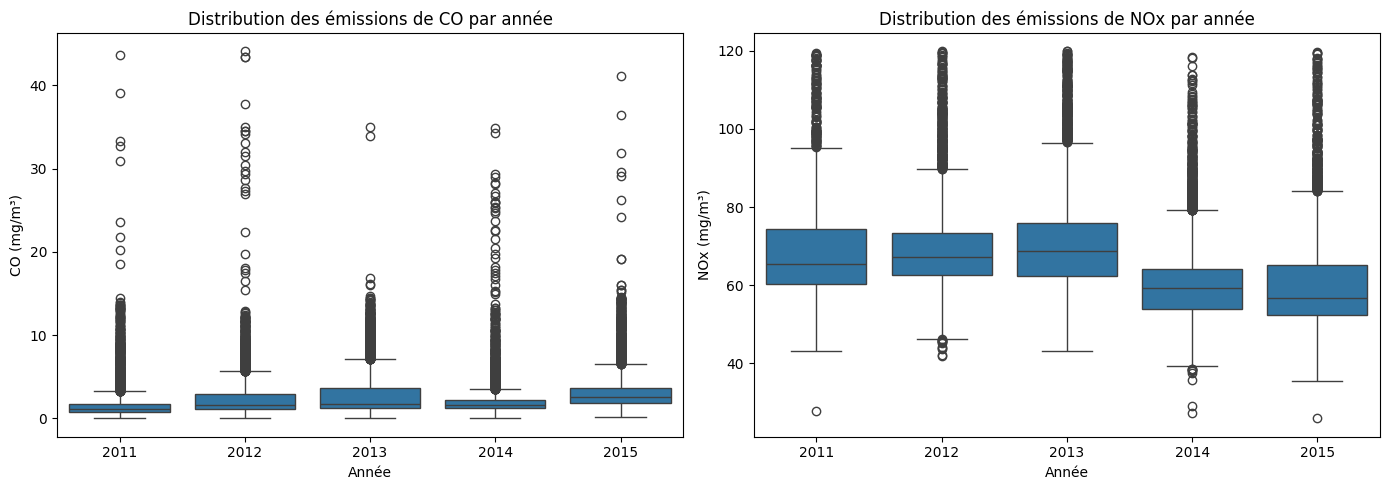

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df,
    x="year",
    y="CO",
    ax=axes[0]
)

axes[0].set_title("Distribution des émissions de CO par année")
axes[0].set_xlabel("Année")
axes[0].set_ylabel("CO (mg/m³)")

sns.boxplot(
    data=df,
    x="year",
    y="NOX",
    ax=axes[1]
)

axes[1].set_title("Distribution des émissions de NOx par année")
axes[1].set_xlabel("Année")
axes[1].set_ylabel("NOx (mg/m³)")

plt.tight_layout()
plt.show()

### Analyse temporelle des émissions (2011–2015)

**Émissions de CO :**
- La concentration moyenne passe de 1,57 mg/m³ en 2011 à 3,13 mg/m³ en 2015.
- Une diminution temporaire est observée en 2014.
- La médiane augmente également, passant de 1,16 à 2,53 mg/m³.
- Des valeurs atypiques élevées sont présentes chaque année.

**Émissions de NOx :**
- Les concentrations moyennes augmentent jusqu'en 2013 (70,01 mg/m³).
- Une baisse importante est observée en 2014 (60,07 mg/m³).
- En 2015, la moyenne reste proche de celle de 2014 (59,89 mg/m³).
- Les distributions de 2014 et 2015 sont décalées vers des concentrations plus faibles.

**Interprétation :**

Les émissions évoluent différemment selon les années. Ces variations peuvent être associées à des changements de conditions environnementales, de charge ou de fonctionnement de la turbine.

**Conclusion :**

Les distributions des émissions ne sont pas stables sur la période 2011–2015. Cette observation justifie une validation chronologique des modèles de Machine Learning afin d'évaluer leur capacité à généraliser à de nouvelles périodes.

In [22]:
features = ["AT", "TIT", "TEY"]

yearly_features = df.groupby("year")[features].mean()

yearly_features

,AT,TIT,TEY
year,,,
2011,17.112261,1084.733909,135.745675
2012,18.397950,1082.890233,132.675552
2013,17.602620,1081.569463,132.168342
2014,18.217071,1078.836854,132.907978
2015,17.225259,1078.974689,133.993380


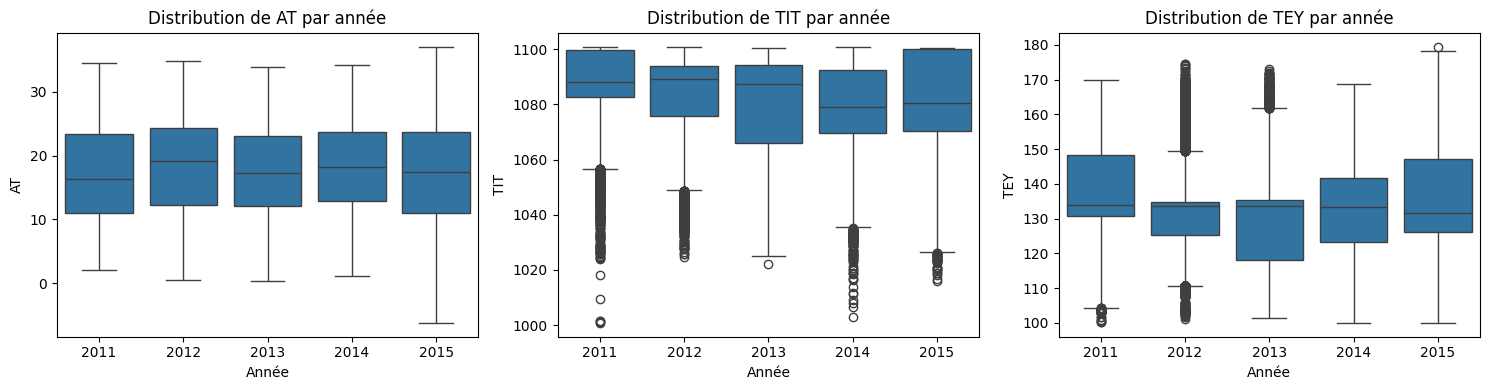

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, features):
    sns.boxplot(
        data=df,
        x="year",
        y=col,
        ax=ax
    )

    ax.set_title(f"Distribution de {col} par année")
    ax.set_xlabel("Année")

plt.tight_layout()
plt.show()

### Analyse des conditions de fonctionnement par année (2011–2015)

**Température ambiante (AT) :**
- Les distributions restent globalement similaires entre les années.
- Les températures moyennes varient entre 17,11 °C et 18,40 °C.
- Aucune rupture annuelle majeure n'est visible dans les moyennes.

**Température d'entrée de la turbine (TIT) :**
- La moyenne diminue progressivement de 1084,73 °C en 2011 à 1078,97 °C en 2015.
- Les distributions présentent des différences de dispersion entre les années.
- Une concentration de mesures près de 1100 °C pourrait indiquer une consigne ou une limite de fonctionnement.

**Production énergétique (TEY) :**
- La production moyenne diminue entre 2011 et 2013, puis augmente légèrement.
- La dispersion montre que la turbine fonctionne à différents niveaux de charge.
- Aucune tendance annuelle strictement croissante ou décroissante n'est observée.

**Conclusion :**

Les paramètres environnementaux et opérationnels présentent des variations entre 2011 et 2015, mais celles-ci n'expliquent pas directement les différences observées dans les émissions de CO et de NOx.

### Préparer les données pour le Machine Learning

In [24]:
feature_columns = [
    "AT", "AP", "AH", "AFDP", "GTEP",
    "TIT", "TAT", "TEY", "CDP"
]

target_columns = ["CO", "NOX"]

X = df[feature_columns].copy()
y = df[target_columns].copy()

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (36733, 9)
Dimensions de y : (36733, 2)


Train (2011–2013) : pour apprendre les relations entre les capteurs et les émissions.

Validation (2014) : pour comparer les modèles et choisir leurs hyperparamètres.

Test (2015) : pour mesurer les performances finales sur une année jamais utilisée pour choisir le modèle.(intact jusqu'à l'évaluation finale.

In [25]:
train_mask = df["year"] <= 2013
val_mask = df["year"] == 2014
test_mask = df["year"] == 2015

X_train = X.loc[train_mask].copy()
X_val = X.loc[val_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_val = y.loc[val_mask].copy()
y_test = y.loc[test_mask].copy()

In [26]:
print("Train :", X_train.shape, y_train.shape)
print("Validation :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)

Train : (22191, 9) (22191, 2)
Validation : (7158, 9) (7158, 2)
Test : (7384, 9) (7384, 2)


In [27]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()), ('model', Ridge())])

In [28]:
y_pred = ridge_model.predict(X_val)

predictions = pd.DataFrame(
    y_pred,
    columns=["CO_pred", "NOX_pred"],
    index=y_val.index
)

predictions.head()

,CO_pred,NOX_pred
22191,2.370174,70.424898
22192,2.423660,70.975141
22193,2.385620,71.236832
22194,2.164141,70.379549
22195,2.401656,70.828794


In [29]:
comparison = pd.concat([
    y_val.rename(columns={
        "CO": "CO_real",
        "NOX": "NOX_real"
    }),
    predictions
], axis=1)

comparison.head(10)

,CO_real,NOX_real,CO_pred,NOX_pred
22191,1.9157,68.292,2.370174,70.424898
22192,2.0596,68.610,2.423660,70.975141
22193,2.1621,68.324,2.385620,71.236832
22194,2.1214,67.619,2.164141,70.379549
22195,2.1549,66.499,2.401656,70.828794
22196,2.1566,67.005,1.986614,68.020480
22197,1.5995,66.593,2.044291,67.375327
22198,1.9358,67.891,2.262341,68.692041
22199,1.8884,68.946,2.020297,67.786202
22200,1.7925,68.853,2.172929,68.193565


In [30]:
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

for i, target in enumerate(target_columns):
    mae = mean_absolute_error(y_val[target], y_pred[:, i])

    rmse = np.sqrt(
        mean_squared_error(y_val[target], y_pred[:, i])
    )

    r2 = r2_score(y_val[target], y_pred[:, i])

    print(f"\nRésultats pour {target}")
    print(f"MAE  : {mae:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"R²   : {r2:.4f}")


Résultats pour CO
MAE  : 0.9081
RMSE : 1.5313
R²   : 0.4178

Résultats pour NOX
MAE  : 6.5353
RMSE : 8.6175
R²   : 0.2531


**CO : MAE = 0,9081 mg/m³.** Les prédictions s'écartent en moyenne d'environ 0,91 mg/m³ des valeurs réelles.

**NOx : MAE = 6,5353 mg/m³.** Les prédictions s'écartent en moyenne d'environ 6,54 mg/m³.

Pour CO, notre modèle explique environ **41,78 %** de la variabilité observée en 2014.

Pour NOx, il explique environ **25,31 %**.

Ridge capture une partie des relations entre les capteurs et les émissions, mais une proportion importante de la variabilité reste inexpliquée, particulièrement pour NOx.

###  Random Forest 

### 1. Pourquoi Random Forest ?

**Random Forest** est un modèle qui combine plusieurs arbres de décision.

* **Apprentissage local :** Chaque arbre apprend des règles à partir des caractéristiques.
* **Force du collectif :** Random Forest construit de nombreux arbres et combine leurs prédictions.

Il peut donc **capturer des relations complexes** entre *TIT*, *TEY*, *CDP* et les autres variables.

### 2. Pourquoi Ridge Regression a-t-elle ces limites ?

Rappelle-toi notre analyse exploratoire. Nous avions découvert que :
* **Non-linéarité :** La relation *TEY–CO* semble non linéaire.
* **Multicollinéarité :** Plusieurs variables, notamment *TEY*, *CDP* et *GTEP*, sont fortement corrélées.
* **Instabilité temporelle :** Les comportements des émissions changent selon les années.

**Ridge** est une régression linéaire avec régularisation L2. Elle apprend essentiellement une relation de la forme :

$$ \hat y = \beta_0 + \beta_1 x_1 + \cdots + \beta_9 x_9 $$


**Limites :** Elle ne peut pas représenter directement des relations complexes ou des interactions non linéaires entre les variables, à moins de créer nous-mêmes des caractéristiques supplémentaires.

Nous allons donc **comparer Ridge avec Random Forest**.


In [31]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=150, # Construit 150 arbres de décision
    min_samples_leaf=2,#Impose au moins 2 observations dans chaque feuille
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

RandomForestRegressor(min_samples_leaf=2, n_estimators=150, n_jobs=-1,
                      random_state=42)

In [32]:
rf_pred = rf_model.predict(X_val)

rf_predictions = pd.DataFrame(
    rf_pred,
    columns=["CO_pred", "NOX_pred"],
    index=y_val.index
)

rf_predictions.head()

,CO_pred,NOX_pred
22191,3.457393,82.849540
22192,2.530372,77.594617
22193,2.167191,75.880678
22194,1.898519,73.584246
22195,1.984454,72.674075


In [33]:
# Prédictions de Random Forest
rf_pred = rf_model.predict(X_val)

# Créer le tableau de comparaison
rf_comparison = pd.DataFrame({
    "CO_real": y_val["CO"],
    "NOX_real": y_val["NOX"],
    "CO_pred": rf_pred[:, 0],
    "NOX_pred": rf_pred[:, 1]
}, index=y_val.index)

# Afficher les 10 premières observations
rf_comparison.head(10)

,CO_real,NOX_real,CO_pred,NOX_pred
22191,1.9157,68.292,3.457393,82.849540
22192,2.0596,68.610,2.530372,77.594617
22193,2.1621,68.324,2.167191,75.880678
22194,2.1214,67.619,1.898519,73.584246
22195,2.1549,66.499,1.984454,72.674075
22196,2.1566,67.005,1.901301,72.120093
22197,1.5995,66.593,2.014004,71.241255
22198,1.9358,67.891,2.209945,73.297958
22199,1.8884,68.946,2.461690,75.527050
22200,1.7925,68.853,2.448001,74.948117


In [34]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

for i, target in enumerate(target_columns):

    mae = mean_absolute_error(
        y_val[target],
        rf_pred[:, i]
    )

    rmse = np.sqrt(
        mean_squared_error(y_val[target], rf_pred[:, i])
    )

    r2 = r2_score(
        y_val[target],
        rf_pred[:, i]
    )

    print(f"\nRésultats Random Forest pour {target}")
    print(f"MAE  : {mae:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"R²   : {r2:.4f}")


Résultats Random Forest pour CO
MAE  : 0.7872
RMSE : 1.5136
R²   : 0.4311

Résultats Random Forest pour NOX
MAE  : 9.1604
RMSE : 10.6224
R²   : -0.1349


In [35]:
def plot_actual_vs_predicted(y_true, y_pred, target_columns, model_name="Model"):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    for ax, target, i in zip(axes, target_columns, range(len(target_columns))):
        actual = y_true[target]
        predicted = y_pred[:, i]

        ax.scatter(actual, predicted, alpha=0.4, s=20)

        lower = min(actual.min(), predicted.min())
        upper = max(actual.max(), predicted.max())

        ax.plot([lower, upper], [lower, upper], linestyle="--", color="black")

        ax.set_title(f"{target}: Actual vs Predicted")
        ax.set_xlabel("Actual")
        ax.set_ylabel("Predicted")

    fig.suptitle(f"{model_name} - Actual vs Predicted", y=1.02)
    plt.tight_layout()
    plt.show()

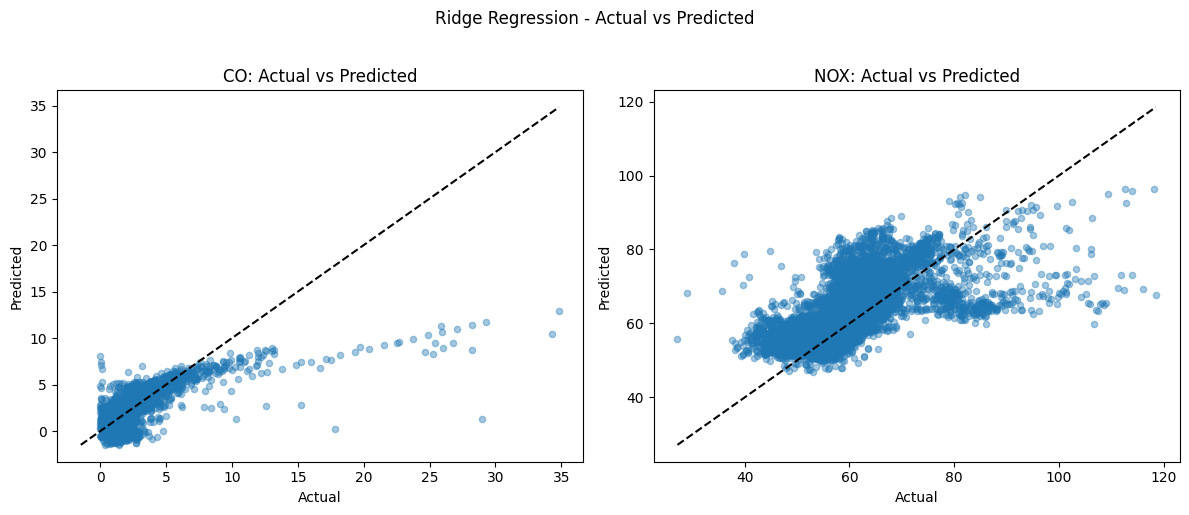

In [36]:
plot_actual_vs_predicted(
    y_true=y_val,
    y_pred=y_pred,
    target_columns=target_columns,
    model_name="Ridge Regression"
)

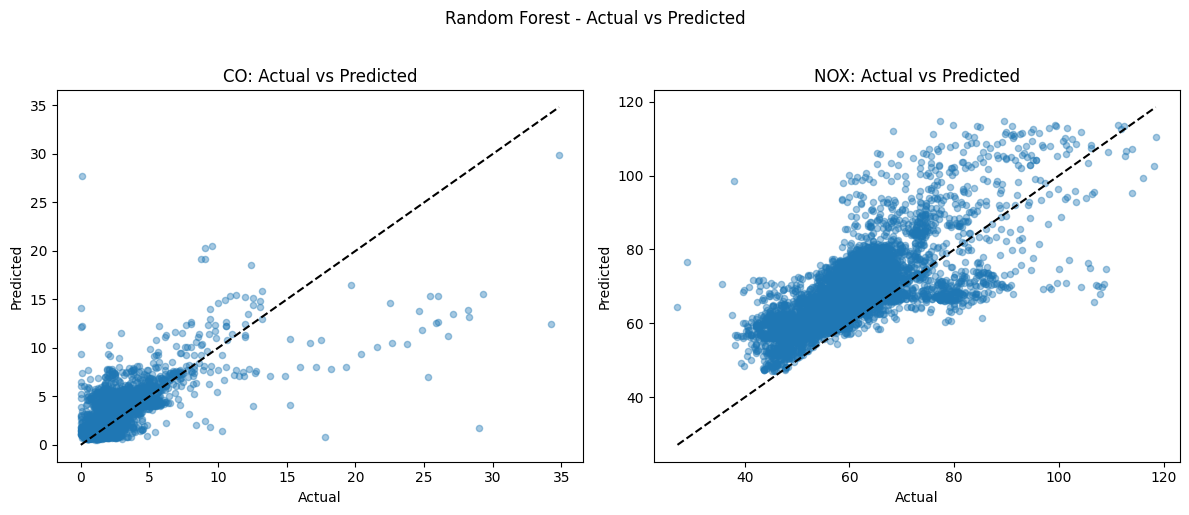

In [37]:
plot_actual_vs_predicted(
    y_true=y_val,
    y_pred=rf_pred,
    target_columns=target_columns,
    model_name="Random Forest"
)

In [38]:
from sklearn.svm import SVR
from sklearn.multioutput import MultiOutputRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Échantillon reproductible de 5000 observations
X_svr_train = X_train.sample(n=5000, random_state=42)
y_svr_train = y_train.loc[X_svr_train.index]

# Définition du modèle
svr_model = MultiOutputRegressor(
    Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVR(
            kernel="rbf",
            C=10.0,
            epsilon=0.1,
            gamma="scale"
        ))
    ])
)

# Entraînement
svr_model.fit(X_svr_train, y_svr_train)

MultiOutputRegressor(estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                               ('model', SVR(C=10.0))]))

In [39]:
svr_pred = svr_model.predict(X_val)

In [40]:
svr_comparison = pd.DataFrame({
    "CO_real": y_val["CO"],
    "NOX_real": y_val["NOX"],
    "CO_pred": svr_pred[:, 0],
    "NOX_pred": svr_pred[:, 1]
}, index=y_val.index)

svr_comparison.head(10)

,CO_real,NOX_real,CO_pred,NOX_pred
22191,1.9157,68.292,3.035473,79.074334
22192,2.0596,68.610,3.063995,78.518776
22193,2.1621,68.324,3.006484,77.824751
22194,2.1214,67.619,2.864678,77.262089
22195,2.1549,66.499,3.159790,77.804880
22196,2.1566,67.005,2.886641,77.116812
22197,1.5995,66.593,3.085549,77.946824
22198,1.9358,67.891,3.195151,78.465467
22199,1.8884,68.946,3.022095,78.396435
22200,1.7925,68.853,3.181504,78.457563


In [41]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

for i, target in enumerate(target_columns):

    mae = mean_absolute_error(
        y_val[target], svr_pred[:, i]
    )

    rmse = np.sqrt(
        mean_squared_error(y_val[target], svr_pred[:, i])
    )

    r2 = r2_score(
        y_val[target], svr_pred[:, i]
    )

    print(f"\nRésultats RBF SVR pour {target}")
    print(f"MAE  : {mae:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"R²   : {r2:.4f}")


Résultats RBF SVR pour CO
MAE  : 1.2442
RMSE : 1.7934
R²   : 0.2014

Résultats RBF SVR pour NOX
MAE  : 9.5032
RMSE : 10.9394
R²   : -0.2037


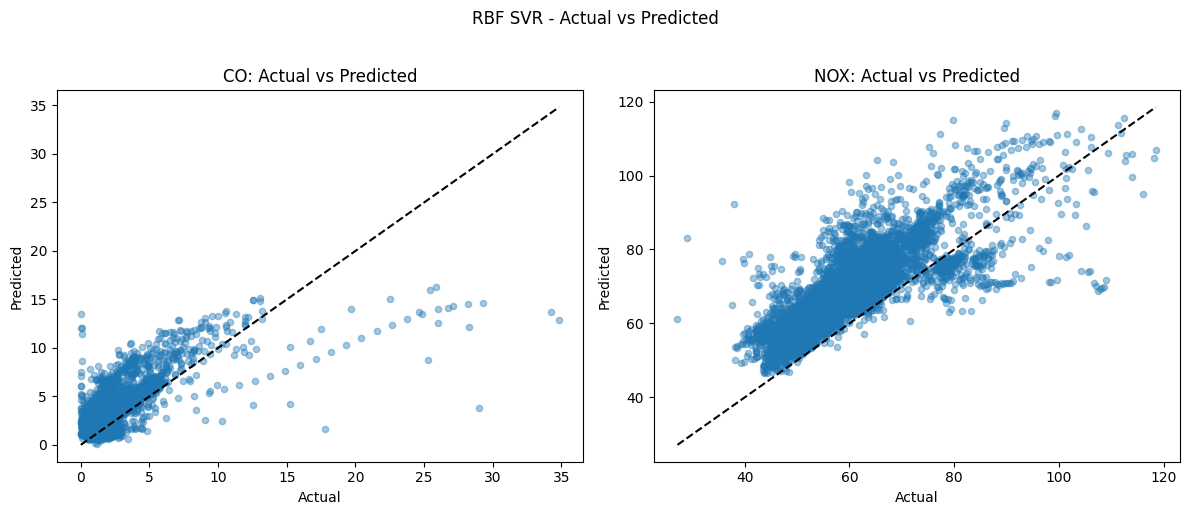

In [42]:
plot_actual_vs_predicted(
    y_true=y_val,
    y_pred=svr_pred,
    target_columns=target_columns,
    model_name="RBF SVR"
)

Target                CO      NOX
Model                            
RBF SVR           1.7934  10.9394
Random Forest     1.5136  10.6224
Ridge Regression  1.5313   8.6175


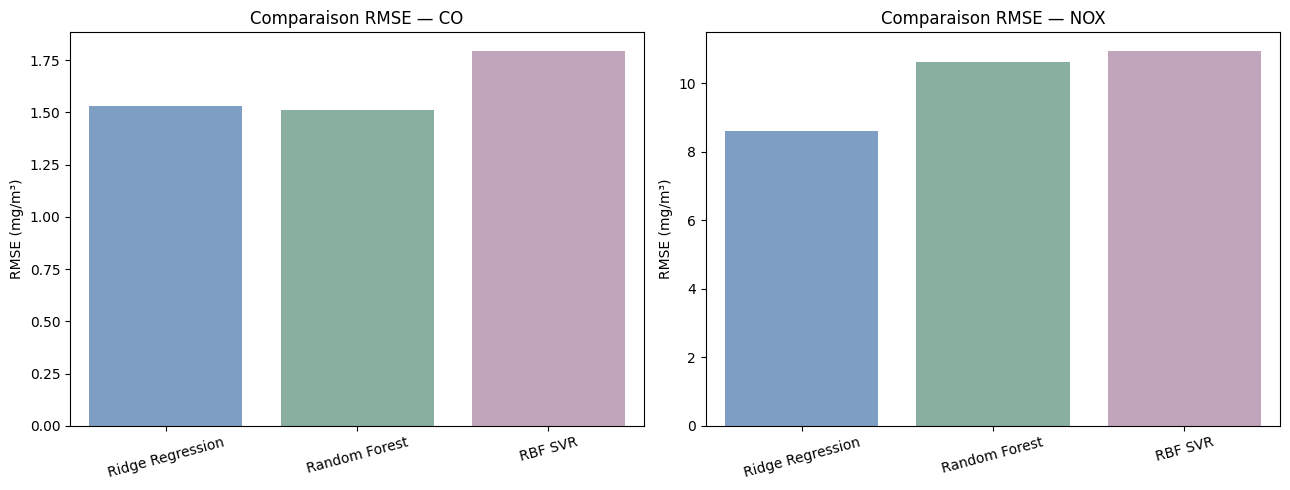

In [43]:
models = {
    "Ridge Regression": ridge_model,
    "Random Forest": rf_model,
    "RBF SVR": svr_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_val)

    for i, target in enumerate(["CO", "NOX"]):
        rmse = np.sqrt(mean_squared_error(y_val[target], y_pred[:, i]))

        results.append({
            "Model": name,
            "Target": target,
            "RMSE": rmse
        })

rmse_df = pd.DataFrame(results)

# Tableau des résultats
print(rmse_df.pivot(index="Model", columns="Target", values="RMSE").round(4))

palette = {
    "Ridge Regression": "#729FCF",  # Bleu doux
    "Random Forest": "#81B5A1",     # Vert sauge
    "RBF SVR": "#C6A0BE"            # Mauve pastel
}

# Ordre des modèles
model_order = ["Ridge Regression", "Random Forest", "RBF SVR"]

# Graphiques
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, target in zip(axes, ["CO", "NOX"]):
    sns.barplot(
        data=rmse_df[rmse_df["Target"] == target],
        x="Model",
        y="RMSE",
        order=model_order,
        hue="Model",
        palette=palette,
        dodge=False,
        legend=False,
        ax=ax
    )

    ax.set_title(f"Comparaison RMSE — {target}")
    ax.set_ylabel("RMSE (mg/m³)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()